In [29]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

In [31]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"])
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

feature_names = X.columns.tolist()


In [32]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

number_of_features = len(feature_names)



In [33]:
categorical_features = []
continuous_features = []

for j in range(number_of_features):

    unique_values = np.unique(X_train[:, j])

    if (
        len(unique_values) <= 10
        and np.allclose(unique_values, np.round(unique_values))
    ):
        categorical_features.append(j)
    else:
        continuous_features.append(j)

feature_types = {}

for j, feature in enumerate(feature_names):

    if j in categorical_features:
        feature_types[feature] = "Categorical / discrete"
    else:
        feature_types[feature] = "Continuous"



In [34]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
baseline_f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)

class_index = list(model.classes_).index(1)

def predict_probability(data):
    return model.predict_proba(data)[:, class_index]


print("MODEL PERFORMANCE")
print("-----------------------------")
print("Accuracy:", round(accuracy, 4))
print("F1 Score:", round(baseline_f1, 4))



MODEL PERFORMANCE
-----------------------------
Accuracy: 0.7705
F1 Score: 0.7879


In [35]:
def calculate_permutation_importance(
    X_validation,
    y_validation,
    repetitions=8,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    baseline_score = f1_score(
        y_validation,
        model.predict(X_validation),
        zero_division=0
    )

    importance_values = np.zeros(number_of_features)
    importance_std = np.zeros(number_of_features)

    for j in range(number_of_features):

        score_drops = []

        for _ in range(repetitions):

            shuffled_data = X_validation.copy()

            shuffled_data[:, j] = rng.permutation(
                shuffled_data[:, j]
            )

            shuffled_predictions = model.predict(
                shuffled_data
            )

            shuffled_score = f1_score(
                y_validation,
                shuffled_predictions,
                zero_division=0
            )

            score_drops.append(
                baseline_score - shuffled_score
            )

        importance_values[j] = np.mean(score_drops)
        importance_std[j] = np.std(score_drops)

    return importance_values, importance_std


permutation_values, permutation_std = (
    calculate_permutation_importance(
        X_test,
        y_test,
        repetitions=8
    )
)


permutation_rank_values = np.maximum(
    permutation_values,
    0
)



In [36]:
rng = np.random.default_rng(42)

background_size = min(40, len(X_train))

background_indices = rng.choice(
    len(X_train),
    size=background_size,
    replace=False
)

background_data = X_train[background_indices]

number_of_explanations = min(20, len(X_test))

explain_data = X_test[:number_of_explanations]


def calculate_manual_shap(
    observation,
    background,
    permutations=40,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    shap_values = np.zeros(number_of_features)

    baseline = np.mean(
        predict_probability(background)
    )

    for _ in range(permutations):

        feature_order = rng.permutation(
            number_of_features
        )

        selected_features = []

        previous_prediction = baseline

        for j in feature_order:

            selected_features.append(j)

            hybrid_data = background.copy()

            hybrid_data[:, selected_features] = (
                observation[selected_features]
            )

            current_prediction = np.mean(
                predict_probability(hybrid_data)
            )

            shap_values[j] += (
                current_prediction - previous_prediction
            )

            previous_prediction = current_prediction

    shap_values /= permutations

    return shap_values


all_shap_values = []

for i, observation in enumerate(explain_data):

    values = calculate_manual_shap(
        observation,
        background_data,
        permutations=40,
        random_state=100 + i
    )

    all_shap_values.append(values)

all_shap_values = np.array(all_shap_values)


shap_global = np.mean(
    np.abs(all_shap_values),
    axis=0
)

shap_variability = np.std(
    all_shap_values,
    axis=0
)



In [37]:
feature_scales = np.std(
    X_train,
    axis=0
)

feature_scales[feature_scales < 1e-10] = 1.0


def generate_local_perturbations(
    observation,
    samples=1500,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    perturbed = np.zeros(
        (samples, number_of_features)
    )

    for j in range(number_of_features):

        if j in categorical_features:

            values, counts = np.unique(
                X_train[:, j],
                return_counts=True
            )

            probabilities = counts / counts.sum()

            perturbed[:, j] = rng.choice(
                values,
                size=samples,
                p=probabilities
            )

        else:

            perturbed[:, j] = rng.normal(
                loc=observation[j],
                scale=0.5 * feature_scales[j],
                size=samples
            )

    perturbed[0] = observation

    return perturbed


def create_local_design(
    perturbed,
    observation
):

    design = np.zeros_like(perturbed, dtype=float)

    for j in range(number_of_features):

        if j in categorical_features:

            design[:, j] = (
                perturbed[:, j] != observation[j]
            ).astype(float)

        else:

            design[:, j] = (
                perturbed[:, j] - observation[j]
            ) / feature_scales[j]

    return design


def calculate_lime_weights(
    design,
    kernel_width=0.75
):

    distances = np.sqrt(
        np.mean(design ** 2, axis=1)
    )

    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    return weights


def train_manual_weighted_surrogate(
    design,
    predictions,
    weights,
    regularization=0.01
):

    sample_count, feature_count = design.shape

    design_matrix = np.column_stack([
        np.ones(sample_count),
        design
    ])

    weighted_mean = np.average(
        predictions,
        weights=weights
    )

   
    weighted_design = (
        design_matrix * np.sqrt(weights[:, None])
    )

    weighted_target = (
        predictions * np.sqrt(weights)
    )

    identity = np.eye(feature_count + 1)
    identity[0, 0] = 0

    coefficients = np.linalg.solve(
        weighted_design.T @ weighted_design
        + regularization * identity,
        weighted_design.T @ weighted_target
    )

    intercept = coefficients[0]
    feature_coefficients = coefficients[1:]

    return intercept, feature_coefficients


def calculate_local_fidelity(
    design,
    predictions,
    weights,
    intercept,
    coefficients
):

    surrogate_predictions = (
        intercept + design @ coefficients
    )

    weighted_mean = np.average(
        predictions,
        weights=weights
    )

    residual = np.sum(
        weights * (predictions - surrogate_predictions) ** 2
    )

    total = np.sum(
        weights * (predictions - weighted_mean) ** 2
    )

    weighted_r2 = (
        1 - residual / total
        if total > 1e-12 else np.nan
    )

    weighted_mae = np.average(
        np.abs(predictions - surrogate_predictions),
        weights=weights
    )

    return weighted_r2, weighted_mae


all_lime_coefficients = []
lime_fidelity_results = []

for i, observation in enumerate(explain_data):

    perturbed = generate_local_perturbations(
        observation,
        samples=1500,
        random_state=200 + i
    )

    design = create_local_design(
        perturbed,
        observation
    )

    weights = calculate_lime_weights(design)

    original_predictions = predict_probability(
        perturbed
    )

    rng = np.random.default_rng(300 + i)

    indices = rng.permutation(len(perturbed))

    split = int(0.70 * len(indices))

    train_indices = indices[:split]
    validation_indices = indices[split:]

    intercept, coefficients = train_manual_weighted_surrogate(
        design[train_indices],
        original_predictions[train_indices],
        weights[train_indices]
    )

    validation_r2, validation_mae = calculate_local_fidelity(
        design[validation_indices],
        original_predictions[validation_indices],
        weights[validation_indices],
        intercept,
        coefficients
    )

    all_lime_coefficients.append(coefficients)

    lime_fidelity_results.append({
        "Observation": i + 1,
        "Weighted R2": validation_r2,
        "Weighted MAE": validation_mae
    })

all_lime_coefficients = np.array(
    all_lime_coefficients
)

lime_fidelity_df = pd.DataFrame(
    lime_fidelity_results
)

lime_global = np.mean(
    np.abs(all_lime_coefficients),
    axis=0
)

lime_variability = np.std(
    all_lime_coefficients,
    axis=0
)



In [38]:


def normalize_importance(values):

    values = np.asarray(values, dtype=float)

    values = np.maximum(values, 0)

    total = np.sum(values)

    if total <= 1e-12:
        return np.zeros_like(values)

    return values / total


permutation_normalized = normalize_importance(
    permutation_rank_values
)

shap_normalized = normalize_importance(
    shap_global
)

lime_normalized = normalize_importance(
    lime_global
)



In [39]:


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Feature Type": [
        feature_types[name] for name in feature_names
    ],
    "Permutation Raw": permutation_values,
    "Permutation Std": permutation_std,
    "SHAP Mean Absolute": shap_global,
    "SHAP Variability": shap_variability,
    "LIME Mean Absolute": lime_global,
    "LIME Variability": lime_variability,
    "Permutation Normalized": permutation_normalized,
    "SHAP Normalized": shap_normalized,
    "LIME Normalized": lime_normalized
})

importance_df["Permutation Rank"] = (
    importance_df["Permutation Normalized"]
    .rank(ascending=False, method="average")
)

importance_df["SHAP Rank"] = (
    importance_df["SHAP Normalized"]
    .rank(ascending=False, method="average")
)

importance_df["LIME Rank"] = (
    importance_df["LIME Normalized"]
    .rank(ascending=False, method="average")
)

importance_df["Average Rank"] = importance_df[
    [
        "Permutation Rank",
        "SHAP Rank",
        "LIME Rank"
    ]
].mean(axis=1)

importance_df["Consensus Rank"] = (
    importance_df["Average Rank"]
    .rank(ascending=True, method="min")
)

importance_df = importance_df.sort_values(
    "Consensus Rank"
).reset_index(drop=True)

importance_df.to_csv(
    "feature_importance_report.csv",
    index=False
)

print("\nGLOBAL FEATURE IMPORTANCE")
print(
    importance_df[
        [
            "Feature",
            "Feature Type",
            "Permutation Rank",
            "SHAP Rank",
            "LIME Rank",
            "Average Rank",
            "Consensus Rank"
        ]
    ].round(3).to_string(index=False)
)




GLOBAL FEATURE IMPORTANCE
 Feature           Feature Type  Permutation Rank  SHAP Rank  LIME Rank  Average Rank  Consensus Rank
      ca Categorical / discrete               2.0        2.0        2.0         2.000             1.0
    thal Categorical / discrete               1.0        4.0        3.0         2.667             2.0
      cp Categorical / discrete               9.5        1.0        1.0         3.833             3.0
     sex Categorical / discrete               3.0        6.0        4.0         4.333             4.0
 thalach             Continuous               9.5        3.0        6.0         6.167             5.0
 oldpeak             Continuous               9.5        5.0        7.0         7.167             6.0
   exang Categorical / discrete               9.5        7.0        5.0         7.167             6.0
   slope Categorical / discrete               4.0       10.0        8.0         7.333             8.0
     age             Continuous               5.0      

In [40]:


local_rows = []

for i in range(number_of_explanations):

    for j, feature in enumerate(feature_names):

        local_rows.append({
            "Observation": i + 1,
            "Feature": feature,
            "SHAP Contribution": all_shap_values[i, j],
            "SHAP Absolute": abs(all_shap_values[i, j]),
            "LIME Coefficient": all_lime_coefficients[i, j],
            "LIME Absolute": abs(all_lime_coefficients[i, j])
        })

local_df = pd.DataFrame(local_rows)

local_df.to_csv(
    "local_feature_importance_report.csv",
    index=False
)

# Average local importance
local_summary = local_df.groupby(
    "Feature"
).agg(
    Mean_SHAP_Contribution=("SHAP Contribution", "mean"),
    Mean_SHAP_Absolute=("SHAP Absolute", "mean"),
    SHAP_Std=("SHAP Contribution", "std"),
    Mean_LIME_Coefficient=("LIME Coefficient", "mean"),
    Mean_LIME_Absolute=("LIME Absolute", "mean"),
    LIME_Std=("LIME Coefficient", "std")
).reset_index()

local_summary.to_csv(
    "local_feature_importance_summary.csv",
    index=False
)



In [41]:


global_local_df = importance_df[
    ["Feature", "Consensus Rank"]
].merge(
    local_summary,
    on="Feature"
)

global_local_df["Local SHAP Rank"] = (
    global_local_df["Mean_SHAP_Absolute"]
    .rank(ascending=False, method="average")
)

global_local_df["Local LIME Rank"] = (
    global_local_df["Mean_LIME_Absolute"]
    .rank(ascending=False, method="average")
)

global_local_df.to_csv(
    "global_vs_local_importance.csv",
    index=False
)

print("\nGLOBAL VS LOCAL IMPORTANCE")
print(
    global_local_df.round(4).to_string(index=False)
)


GLOBAL VS LOCAL IMPORTANCE
 Feature  Consensus Rank  Mean_SHAP_Contribution  Mean_SHAP_Absolute  SHAP_Std  Mean_LIME_Coefficient  Mean_LIME_Absolute  LIME_Std  Local SHAP Rank  Local LIME Rank
      ca             1.0                  0.0250              0.0739    0.0744                -0.0886              0.1483    0.1279              2.0              2.0
    thal             2.0                  0.0145              0.0606    0.0647                -0.0378              0.1357    0.1396              4.0              3.0
      cp             3.0                  0.0306              0.1117    0.1147                -0.0207              0.1689    0.1748              1.0              1.0
     sex             4.0                  0.0099              0.0452    0.0513                 0.0108              0.1068    0.1149              6.0              4.0
 thalach             5.0                  0.0056              0.0638    0.0744                 0.0495              0.0495    0.0272           

In [42]:


def manual_pearson(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    x_centered = x - np.mean(x)
    y_centered = y - np.mean(y)

    denominator = np.sqrt(
        np.sum(x_centered ** 2)
        * np.sum(y_centered ** 2)
    )

    if denominator < 1e-12:
        return np.nan

    return np.sum(
        x_centered * y_centered
    ) / denominator


def manual_spearman(x, y):

    x_rank = pd.Series(x).rank(
        method="average"
    ).to_numpy()

    y_rank = pd.Series(y).rank(
        method="average"
    ).to_numpy()

    return manual_pearson(x_rank, y_rank)


rank_comparisons = {
    "Permutation vs SHAP": (
        importance_df["Permutation Rank"],
        importance_df["SHAP Rank"]
    ),
    "Permutation vs LIME": (
        importance_df["Permutation Rank"],
        importance_df["LIME Rank"]
    ),
    "SHAP vs LIME": (
        importance_df["SHAP Rank"],
        importance_df["LIME Rank"]
    )
}

rank_results = []

for comparison_name, (rank_a, rank_b) in rank_comparisons.items():

    rank_results.append({
        "Comparison": comparison_name,
        "Spearman Rank Correlation": manual_spearman(
            rank_a,
            rank_b
        )
    })

rank_df = pd.DataFrame(rank_results)

rank_df.to_csv(
    "interpretability_rank_correlations.csv",
    index=False
)

print("\nRANK AGREEMENT")
print(rank_df.round(4).to_string(index=False))





RANK AGREEMENT
         Comparison  Spearman Rank Correlation
Permutation vs SHAP                     0.3038
Permutation vs LIME                     0.4229
       SHAP vs LIME                     0.9011


In [43]:


selected_count = min(5, number_of_features)

selected_features = importance_df.head(
    selected_count
)["Feature"].tolist()

print("\nTOP FEATURES SELECTED BY CONSENSUS")
for rank, feature in enumerate(selected_features, start=1):
    print(rank, feature)

# Check how consistently each feature ranks near the top
top_k = min(5, number_of_features)

importance_df["Top 5 Votes"] = (
    (importance_df["Permutation Rank"] <= top_k).astype(int)
    + (importance_df["SHAP Rank"] <= top_k).astype(int)
    + (importance_df["LIME Rank"] <= top_k).astype(int)
)



TOP FEATURES SELECTED BY CONSENSUS
1 ca
2 thal
3 cp
4 sex
5 thalach


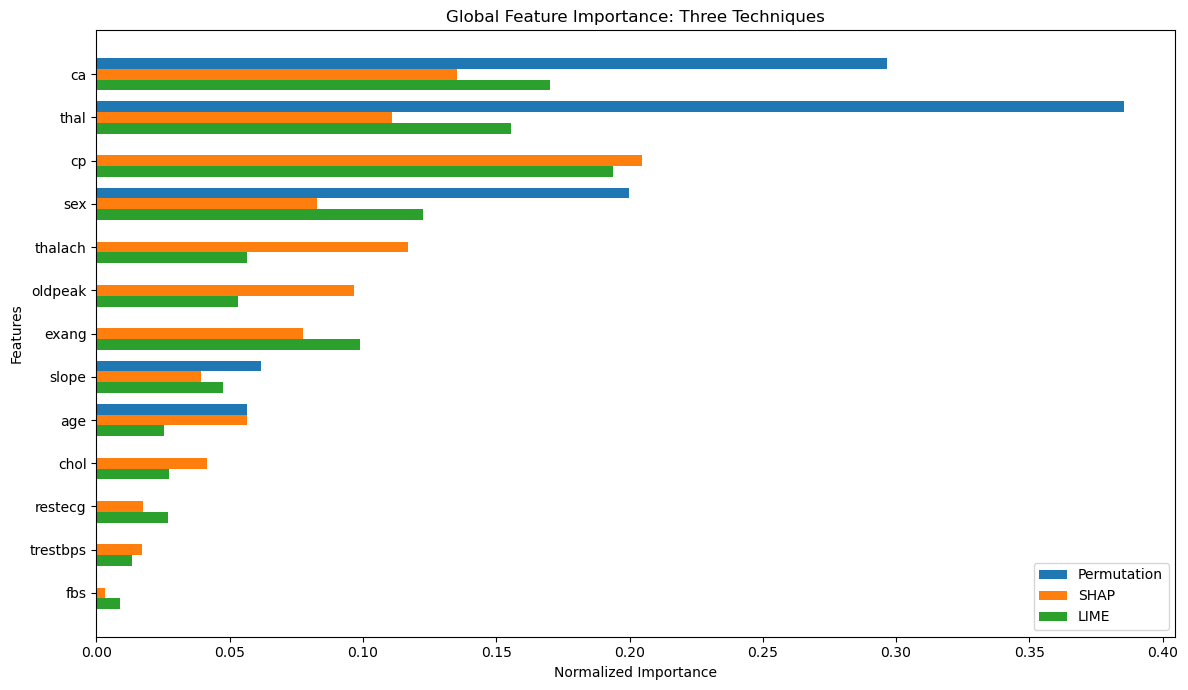

In [44]:


plot_df = importance_df.sort_values(
    "Consensus Rank",
    ascending=True
)

plt.figure(figsize=(12, 7))

y_positions = np.arange(len(plot_df))
width = 0.25

plt.barh(
    y_positions - width,
    plot_df["Permutation Normalized"],
    height=width,
    label="Permutation"
)

plt.barh(
    y_positions,
    plot_df["SHAP Normalized"],
    height=width,
    label="SHAP"
)

plt.barh(
    y_positions + width,
    plot_df["LIME Normalized"],
    height=width,
    label="LIME"
)

plt.yticks(
    y_positions,
    plot_df["Feature"]
)

plt.gca().invert_yaxis()

plt.xlabel("Normalized Importance")
plt.ylabel("Features")
plt.title("Global Feature Importance: Three Techniques")
plt.legend()
plt.tight_layout()
plt.savefig("global_feature_importance.png", dpi=150)
plt.show()



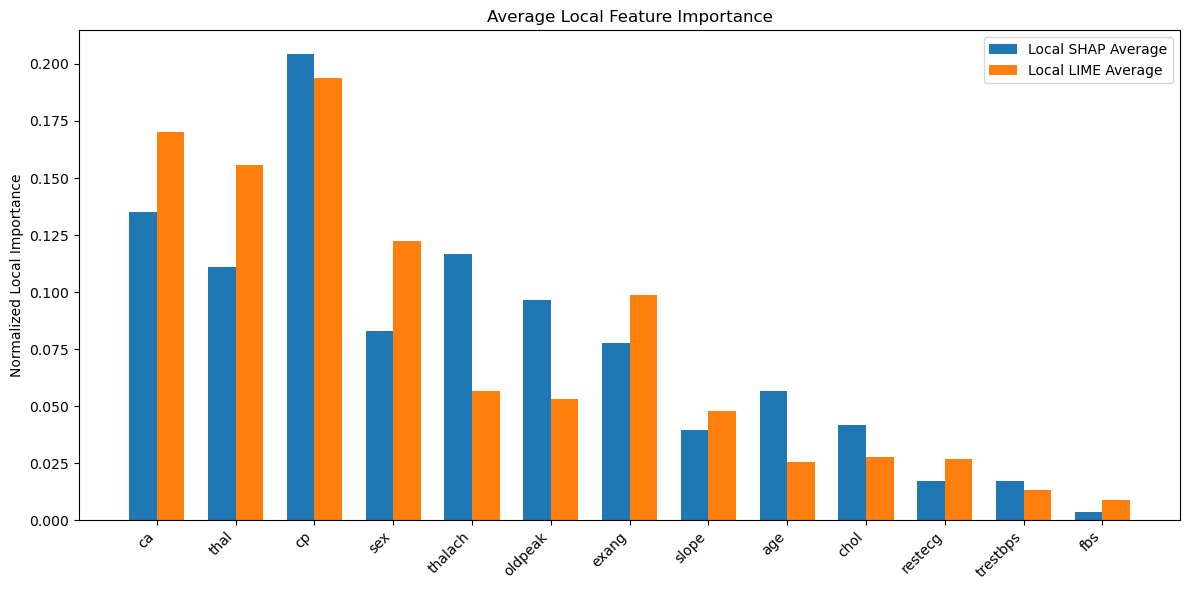

In [45]:


plt.figure(figsize=(12, 6))

x_positions = np.arange(number_of_features)
width = 0.35

plt.bar(
    x_positions - width / 2,
    normalize_importance(
        global_local_df["Mean_SHAP_Absolute"]
    ),
    width,
    label="Local SHAP Average"
)

plt.bar(
    x_positions + width / 2,
    normalize_importance(
        global_local_df["Mean_LIME_Absolute"]
    ),
    width,
    label="Local LIME Average"
)

plt.xticks(
    x_positions,
    global_local_df["Feature"],
    rotation=45,
    ha="right"
)

plt.ylabel("Normalized Local Importance")
plt.title("Average Local Feature Importance")
plt.legend()
plt.tight_layout()
plt.savefig("local_feature_importance.png", dpi=150)
plt.show()

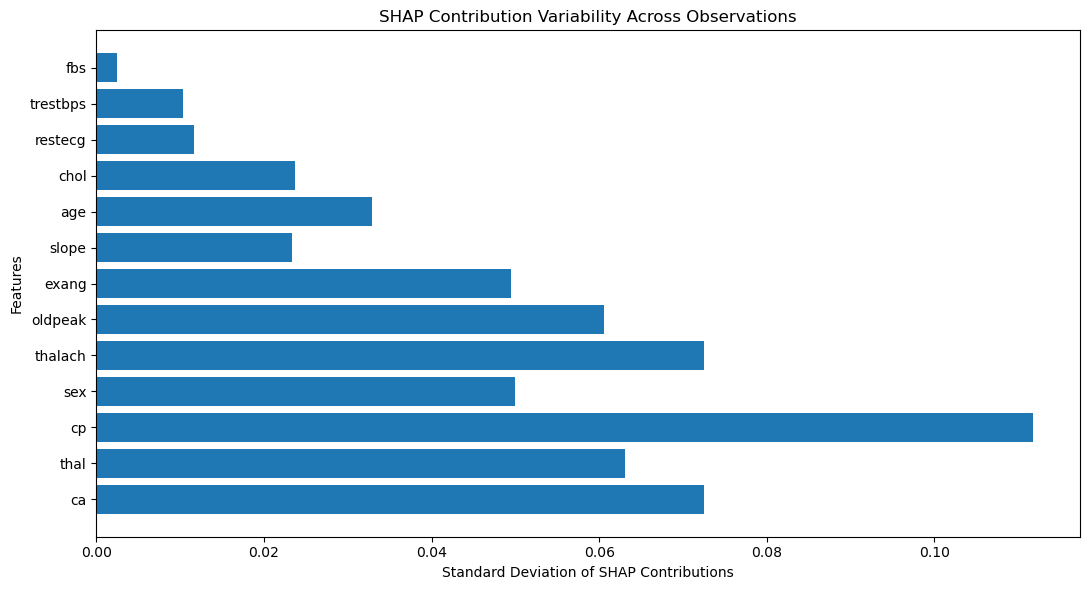

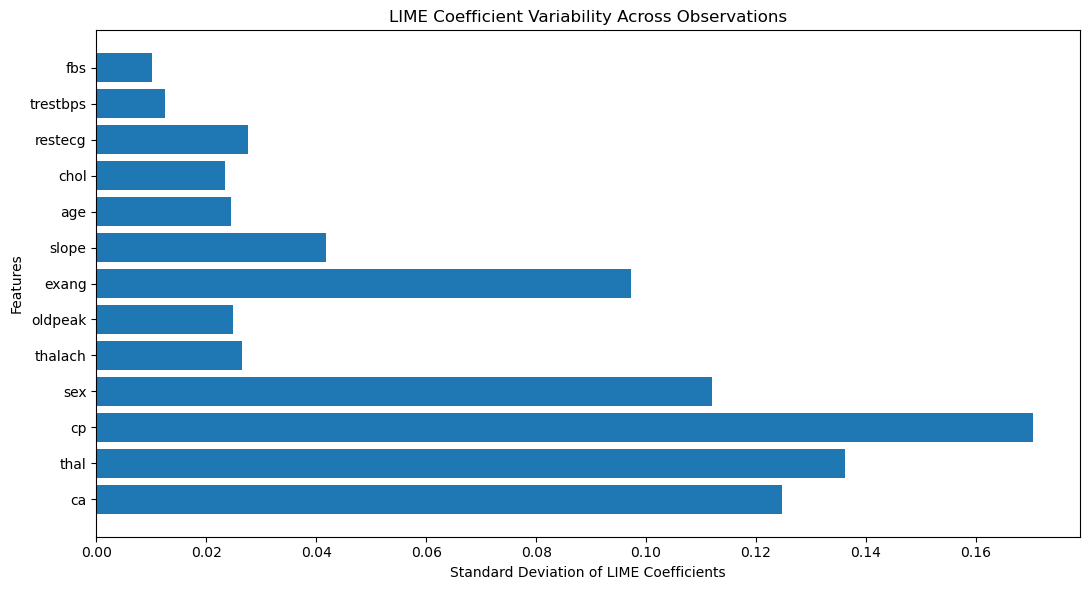

In [46]:


plt.figure(figsize=(11, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["SHAP Variability"],
    label="SHAP Variability"
)

plt.xlabel("Standard Deviation of SHAP Contributions")
plt.ylabel("Features")
plt.title("SHAP Contribution Variability Across Observations")
plt.tight_layout()
plt.savefig("shap_feature_variability.png", dpi=150)
plt.show()

plt.figure(figsize=(11, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["LIME Variability"],
    label="LIME Variability"
)

plt.xlabel("Standard Deviation of LIME Coefficients")
plt.ylabel("Features")
plt.title("LIME Coefficient Variability Across Observations")
plt.tight_layout()
plt.savefig("lime_feature_variability.png", dpi=150)
plt.show()



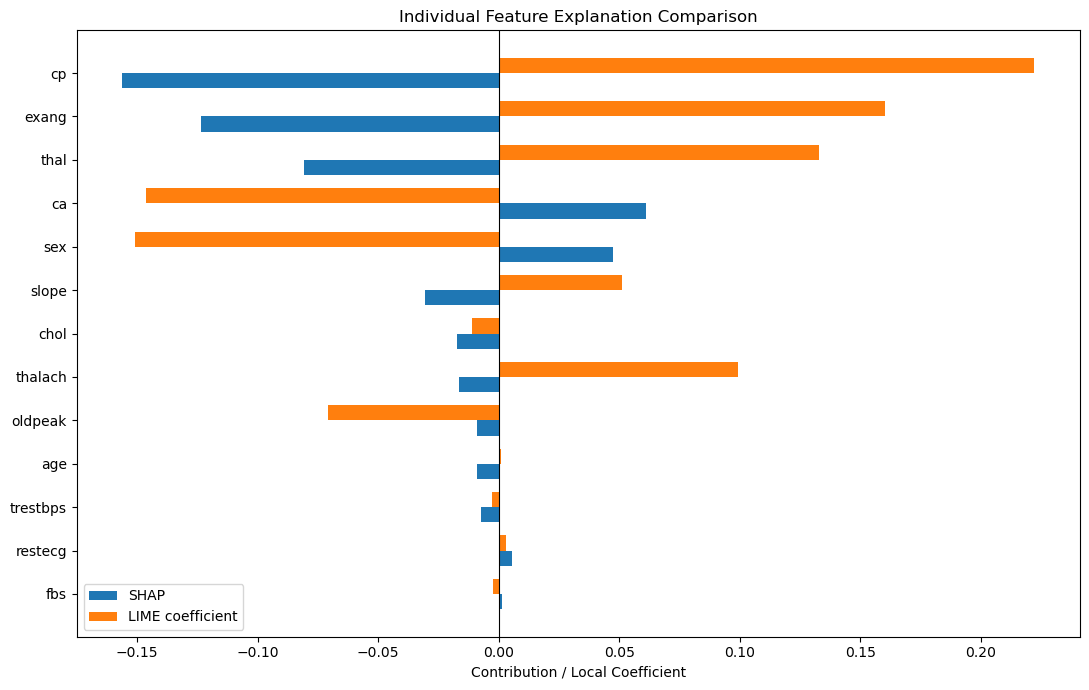

In [47]:


observation_number = 0

individual_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Contribution": all_shap_values[observation_number],
    "LIME Coefficient": all_lime_coefficients[observation_number]
})

individual_df = individual_df.sort_values(
    "SHAP Contribution",
    key=lambda values: np.abs(values),
    ascending=True
)

plt.figure(figsize=(11, 7))

positions = np.arange(len(individual_df))
width = 0.35

plt.barh(
    positions - width / 2,
    individual_df["SHAP Contribution"],
    height=width,
    label="SHAP"
)

plt.barh(
    positions + width / 2,
    individual_df["LIME Coefficient"],
    height=width,
    label="LIME coefficient"
)

plt.yticks(
    positions,
    individual_df["Feature"]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Contribution / Local Coefficient")
plt.title("Individual Feature Explanation Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("individual_explanation_comparison.png", dpi=150)
plt.show()

In [48]:

print("\nLIME SURROGATE VALIDATION")
print(lime_fidelity_df.round(4).to_string(index=False))

average_lime_r2 = lime_fidelity_df["Weighted R2"].mean()
average_lime_mae = lime_fidelity_df["Weighted MAE"].mean()




LIME SURROGATE VALIDATION
 Observation  Weighted R2  Weighted MAE
           1       0.8142        0.0728
           2       0.4548        0.1077
           3       0.6765        0.0771
           4       0.6498        0.0958
           5       0.7005        0.0782
           6       0.6525        0.0785
           7       0.6522        0.0934
           8       0.7988        0.0580
           9       0.6279        0.1016
          10       0.3850        0.1138
          11       0.5991        0.0956
          12       0.6681        0.0948
          13       0.6186        0.1014
          14       0.5081        0.1287
          15       0.7516        0.0775
          16       0.2895        0.1270
          17       0.6108        0.1017
          18       0.8497        0.0627
          19       0.6267        0.1054
          20       0.7469        0.0723


In [49]:

report_lines = []

report_lines.append("# Feature Importance and Interpretability Report")
report_lines.append("")
report_lines.append("## 1. Objective")
report_lines.append(
    "This report evaluates feature contributions in a Random Forest "
    "classification model using permutation importance, approximate "
    "Shapley values, and a manually implemented LIME-style surrogate."
)
report_lines.append("")
report_lines.append("## 2. Dataset and model")
report_lines.append(f"- Dataset observations: {len(df)}")
report_lines.append(f"- Number of features: {number_of_features}")
report_lines.append(f"- Training observations: {len(X_train)}")
report_lines.append(f"- Test observations: {len(X_test)}")
report_lines.append("- Model: Random Forest Classifier")
report_lines.append(f"- Test accuracy: {accuracy:.4f}")
report_lines.append(f"- Test F1 score: {baseline_f1:.4f}")
report_lines.append("")
report_lines.append("## 3. Interpretability methods")
report_lines.append(
    "### Permutation importance\n"
    "Each test feature was shuffled independently. The reduction in "
    "test F1 score was measured over repeated shuffles. Larger positive "
    "reductions indicate greater dependence of model performance on that feature."
)
report_lines.append(
    "### Approximate SHAP values\n"
    "Feature marginal contributions were estimated over random feature "
    "permutations and averaged across background observations. Global "
    "importance is the mean absolute contribution."
)
report_lines.append(
    "### LIME-style local surrogate\n"
    "Synthetic observations were generated around selected test records. "
    "A manually fitted weighted linear model approximated the Random Forest "
    "probability predictions in each local neighborhood."
)
report_lines.append("")
report_lines.append("## 4. Global feature importance ranking")
report_lines.append(
    importance_df[
        [
            "Feature",
            "Feature Type",
            "Permutation Rank",
            "SHAP Rank",
            "LIME Rank",
            "Average Rank",
            "Top 5 Votes"
        ]
    ].to_markdown(index=False)
)
report_lines.append("")
report_lines.append("## 5. Global and local importance comparison")
report_lines.append(
    global_local_df[
        [
            "Feature",
            "Consensus Rank",
            "Mean_SHAP_Absolute",
            "Mean_LIME_Absolute",
            "Local SHAP Rank",
            "Local LIME Rank"
        ]
    ].to_markdown(index=False)
)
report_lines.append("")
report_lines.append("## 6. Agreement between interpretability methods")
report_lines.append(rank_df.to_markdown(index=False))
report_lines.append("")
report_lines.append(
    "Rank correlations measure whether the techniques order features "
    "similarly. They do not prove that the explanations are correct or causal."
)
report_lines.append("")
report_lines.append("## 7. Local surrogate validation")
report_lines.append(lime_fidelity_df.to_markdown(index=False))
report_lines.append("")
report_lines.append(
    f"- Average local weighted R-squared: {average_lime_r2:.4f}"
)
report_lines.append(
    f"- Average local weighted MAE: {average_lime_mae:.4f}"
)
report_lines.append("")
report_lines.append("## 8. Feature selection justification")
report_lines.append(
    "The following features were selected using the average rank of "
    "permutation importance, SHAP and LIME. This consensus ranking reduces "
    "dependence on any single interpretability technique."
)
report_lines.append("")

for rank, feature in enumerate(selected_features, start=1):

    row = importance_df[
        importance_df["Feature"] == feature
    ].iloc[0]

    report_lines.append(
        f"{rank}. **{feature}** ({row['Feature Type']}): "
        f"consensus rank {row['Consensus Rank']:.1f}; "
        f"top-five votes {int(row['Top 5 Votes'])}/3."
    )

report_lines.append("")
report_lines.append("## 9. Feature type limitations")
report_lines.append(
    "- Continuous features: permutation and Gaussian perturbations can "
    "produce unrealistic combinations or values outside realistic ranges."
)
report_lines.append(
    "- Binary and categorical features: numerical encoding can impose "
    "artificial ordering. Category-aware perturbations are preferable."
)
report_lines.append(
    "- Correlated features: independently shuffling or replacing a feature "
    "can break real relationships and distribute importance unpredictably."
)
report_lines.append(
    "- LIME: local linear coefficients depend on perturbation scale, "
    "kernel width, sample count and random seed."
)
report_lines.append(
    "- SHAP: the permutation approximation depends on background selection "
    "and the number of sampled permutations."
)
report_lines.append("")
report_lines.append("## 10. Recommendations")
report_lines.append(
    "Features consistently ranked highly across the three methods are "
    "strong candidates for further investigation. Features with unstable "
    "rankings should not be removed solely because one method assigns them "
    "low importance. Before reducing the feature set, retrain and evaluate "
    "the model using cross-validation and an untouched test set."
)
report_lines.append("")
report_lines.append("## 11. Conclusion")
report_lines.append(
    "The consensus ranking provides a comparative view of global feature "
    "importance, while SHAP and LIME observations provide local explanations. "
    "Feature selection should consider predictive performance, stability, "
    "data quality, interpretability and deployment requirements. Importance "
    "scores describe model behavior and do not establish causal effects."
)
report_lines.append("")
report_lines.append("## 12. Generated files")
report_lines.append("- feature_importance_report.csv")
report_lines.append("- local_feature_importance_report.csv")
report_lines.append("- local_feature_importance_summary.csv")
report_lines.append("- global_vs_local_importance.csv")
report_lines.append("- interpretability_rank_correlations.csv")
report_lines.append("- global_feature_importance.png")
report_lines.append("- local_feature_importance.png")
report_lines.append("- shap_feature_variability.png")
report_lines.append("- lime_feature_variability.png")
report_lines.append("- individual_explanation_comparison.png")

report_text = "\n".join(report_lines)

with open(
    "feature_importance_technical_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(report_text)

In [50]:
print("\nFEATURE IMPORTANCE REPORT GENERATED")
print("------------------------------------------")

print("Top selected features:")
for feature in selected_features:
    print("-", feature)

print("\nGenerated technical report:")
print("feature_importance_technical_report.md")

print("\nGenerated CSV reports:")
print("- feature_importance_report.csv")
print("- local_feature_importance_report.csv")
print("- local_feature_importance_summary.csv")
print("- global_vs_local_importance.csv")
print("- interpretability_rank_correlations.csv")

print("\nFeature importance analysis completed successfully.")


FEATURE IMPORTANCE REPORT GENERATED
------------------------------------------
Top selected features:
- ca
- thal
- cp
- sex
- thalach

Generated technical report:
feature_importance_technical_report.md

Generated CSV reports:
- feature_importance_report.csv
- local_feature_importance_report.csv
- local_feature_importance_summary.csv
- global_vs_local_importance.csv
- interpretability_rank_correlations.csv

Feature importance analysis completed successfully.
